# Machine learning : scoring des communes et typologie des stations

Le notebook comporte deux parties : un **scoring supervisé** des communes (comparaison de trois modèles par GridSearchCV), puis un **clustering non supervisé** des stations (K-Means), en fin de notebook.

## Partie 1 : repérer les communes sans borne au profil de commune équipée

**Question posée au modèle.** Au vu de son profil, une commune devrait-elle avoir au moins un point de charge ? Les communes **sans point** dont le profil ressemble à celui des communes équipées forment une liste de territoires prioritaires pour de futurs déploiements (axe 3 de la problématique : scoring des zones sous-équipées).

**Target.** `equipee` = 1 si la commune a au moins un point de charge (31,0 % des communes de métropole).

**Features.**

| Variable | Source | Justification |
|---|---|---|
| Population (logarithme) | Table communale | Taille de la commune ; le logarithme réduit l'écart entre villages et grandes villes |
| Densité (logarithme) | Population / superficie de la commune | Distinction ville / campagne |
| Latitude, longitude | Centre de la commune | Position géographique |
| Type de commune dans l'aire d'attraction des villes | Référentiel communal 2025 (INSEE) | Commune-centre, pôle, couronne, hors attraction |
| Appartenance à une unité urbaine | Référentiel communal 2025 | Continuité du bâti |
| Zone de montagne | Référentiel communal 2025 | Contraintes du relief |
| Région | Table communale | Politiques régionales de déploiement |

**Features écartées.**
- *Distance au point le plus proche, nombre de points et de stations* : elles contiennent la réponse (data leakage).
- *Superficie* : liée mathématiquement à la population et à la densité, elle rendait les coefficients incohérents (population −1,07, superficie +2,05, densité +3,12 dans un premier essai) et faisait monter artificiellement la probabilité des très grandes communes peu peuplées (Saint-Élie, en Guyane, 157 habitants : probabilité 1,00 avec la superficie, 0,01 sans).

**Périmètre.** Métropole uniquement (34 739 communes). Les 129 communes d'outre-mer sont écartées : leurs coordonnées sont toutes hors du domaine d'apprentissage (contrôle en fin de notebook).

**Validation.** Les communes voisines se ressemblent : mélanger des communes d'un même département entre train et test donnerait un score trop optimiste. La validation se fait donc par **groupes de départements** :
- 20 % des départements sont tenus à l'écart pour le test final ;
- sur les 80 % restants, GridSearchCV règle les hyperparamètres de chaque modèle par cross-validation en 5 groupes de départements (GroupKFold).

**Data leakage.** Les transformations faites avec pandas avant le train / test split (logarithme de la population, densité = population / superficie) sont calculées commune par commune, sans aucune statistique tirée des autres communes : elles ne font passer aucune information du test vers le train. Les étapes qui apprennent des statistiques sur les données (StandardScaler : moyenne et écart-type ; OneHotEncoder : liste des modalités) sont dans le pipeline scikit-learn : elles sont ajustées sur le train seul, à chaque pli de cross-validation. La target n'a jamais été complétée : elle compte des points de charge publiés.

**Métriques.** AUC (capacité à classer les communes équipées avant les autres : 0,5 = hasard, 1 = parfait), average precision (qualité du classement des communes équipées), F1-score au threshold de 0,5 (équilibre entre communes équipées manquées et fausses alertes).

**Règle de choix fixée avant les résultats.** Le meilleur AUC sur les départements de test l'emporte ; si l'écart avec la Logistic Regression est inférieur à 0,01, la Logistic Regression est retenue, car elle est plus simple et ses coefficients se lisent directement.

In [1]:
# Système et fichiers
import json
import time
import warnings
from pathlib import Path

# Manipulation de données et géographie
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely.geometry import shape

# Machine learning
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (adjusted_rand_score, average_precision_score, f1_score,
                             roc_auc_score, silhouette_score)
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")


## Données

In [2]:
CHEMIN_COMMUNES = Path("../data/processed/communes_population_clean.csv")
CHEMIN_REFERENTIEL = Path("../data/raw/referentiel_communes.csv")
DEPARTEMENTS_OUTRE_MER = ["971", "972", "973", "974", "976"]
GRAINE = 42

communes = pd.read_csv(CHEMIN_COMMUNES, dtype={"code_insee": str, "code_departement": str})
referentiel = pd.read_csv(CHEMIN_REFERENTIEL, sep=";", dtype=str,
                          usecols=["com_code", "com_cateaav2020_name", "com_uu2020_status",
                                   "com_is_mountain_area", "geo_shape"])
# Superficie calculée dans une projection à surfaces conservées, utilisée seulement pour la densité
superficie_km2 = gpd.GeoSeries(referentiel["geo_shape"].map(lambda s: shape(json.loads(s))),
                               crs=4326).to_crs(6933).area / 1e6
referentiel = referentiel.drop(columns="geo_shape").assign(superficie_km2=superficie_km2)

donnees = communes.merge(referentiel, left_on="code_insee", right_on="com_code", how="left")
donnees = donnees.rename(columns={"com_cateaav2020_name": "type_commune_aav",
                                  "com_uu2020_status": "unite_urbaine",
                                  "com_is_mountain_area": "zone_montagne"})
donnees["log_population"] = np.log1p(donnees["population"])
donnees["log_densite"] = np.log1p(donnees["population"] / donnees["superficie_km2"])
donnees["equipee"] = (donnees["nb_pdc"] > 0).astype(int)

outre_mer = donnees["code_departement"].isin(DEPARTEMENTS_OUTRE_MER)
metropole = donnees.loc[~outre_mer].reset_index(drop=True)
print(f"Communes : {len(donnees):,} | métropole : {len(metropole):,} | outre-mer écarté : {outre_mer.sum()}")
print(f"Communes équipées (métropole) : {metropole['equipee'].mean() * 100:.1f} %")
print("Valeurs manquantes des variables :",
      metropole[["type_commune_aav", "unite_urbaine", "zone_montagne"]].isna().sum().to_dict())


Communes : 34,868 | métropole : 34,739 | outre-mer écarté : 129
Communes équipées (métropole) : 31.0 %
Valeurs manquantes des variables : {'type_commune_aav': 0, 'unite_urbaine': 0, 'zone_montagne': 0}


## Train / test split par département

In [3]:
VARIABLES_NUMERIQUES = ["log_population", "log_densite", "latitude", "longitude"]
VARIABLES_CATEGORIELLES = ["type_commune_aav", "unite_urbaine", "zone_montagne", "region"]
X = metropole[VARIABLES_NUMERIQUES + VARIABLES_CATEGORIELLES]
y = metropole["equipee"]
groupes = metropole["code_departement"]

# Départements de test tenus à l'écart de tout réglage (20 % des départements)
decoupe = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=GRAINE)
index_entrainement, index_test = next(decoupe.split(X, y, groupes))
X_train, X_test = X.iloc[index_entrainement], X.iloc[index_test]
y_train, y_test = y.iloc[index_entrainement], y.iloc[index_test]
groupes_train = groupes.iloc[index_entrainement]
print(f"Entraînement : {len(X_train):,} communes, {groupes_train.nunique()} départements | "
      f"test : {len(X_test):,} communes, {groupes.iloc[index_test].nunique()} départements")
print("Départements de test :", sorted(groupes.iloc[index_test].unique()))

preparation = ColumnTransformer([
    ("numeriques", StandardScaler(), VARIABLES_NUMERIQUES),
    ("categorielles", OneHotEncoder(handle_unknown="ignore"), VARIABLES_CATEGORIELLES),
])


Entraînement : 27,547 communes, 76 départements | test : 7,192 communes, 20 départements
Départements de test : ['01', '05', '11', '13', '19', '24', '28', '30', '31', '33', '42', '53', '64', '69', '73', '77', '79', '80', '85', '94']


## Comparaison de trois modèles par GridSearch

| Modèle | Hyperparamètres testés |
|---|---|
| Logistic Regression | `C` (régularisation, 0,01 à 10), `class_weight` |
| Random Forest (`n_estimators` = 300) | `max_depth`, `min_samples_leaf` |
| XGBoost | `max_depth`, `learning_rate`, `n_estimators` |

Une Logistic Regression sur la seule population sert de **baseline** : un modèle n'a d'intérêt que s'il fait mieux qu'elle.

In [4]:
modeles = {
    "Logistic Regression": (
        LogisticRegression(max_iter=3000),
        {"modele__C": [0.01, 0.1, 1, 10], "modele__class_weight": [None, "balanced"]}),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=GRAINE),
        {"modele__max_depth": [10, 20, None], "modele__min_samples_leaf": [5, 20]}),
    "XGBoost": (
        XGBClassifier(n_jobs=-1, random_state=GRAINE, eval_metric="logloss"),
        {"modele__max_depth": [3, 5], "modele__learning_rate": [0.05, 0.1],
         "modele__n_estimators": [200, 400]}),
}

resultats, meilleurs = [], {}
validation = GroupKFold(n_splits=5)
for nom, (estimateur, grille) in modeles.items():
  debut = time.time()
  recherche = GridSearchCV(Pipeline([("preparation", preparation), ("modele", estimateur)]),
                           grille, scoring="roc_auc", cv=validation, n_jobs=1)
  recherche.fit(X_train, y_train, groups=groupes_train)
  meilleurs[nom] = recherche.best_estimator_
  proba_test = recherche.predict_proba(X_test)[:, 1]
  ecart_type = recherche.cv_results_["std_test_score"][recherche.best_index_]
  resultats.append({
      "modèle": nom,
      "best_params": {k.replace("modele__", ""): v for k, v in recherche.best_params_.items()},
      "AUC validation": f"{recherche.best_score_:.3f} ± {ecart_type:.3f}",
      "AUC test": round(roc_auc_score(y_test, proba_test), 3),
      "average precision test": round(average_precision_score(y_test, proba_test), 3),
      "F1 test (threshold 0,5)": round(f1_score(y_test, proba_test >= 0.5), 3),
      "durée (s)": round(time.time() - debut),
  })

# Référence : la population seule
reference = Pipeline([("preparation", ColumnTransformer([("p", StandardScaler(), ["log_population"])])),
                      ("modele", LogisticRegression(max_iter=3000))]).fit(X_train, y_train)
proba_reference = reference.predict_proba(X_test)[:, 1]
resultats.append({"modèle": "Baseline : population seule", "best_params": "-",
                  "AUC validation": "-", "AUC test": round(roc_auc_score(y_test, proba_reference), 3),
                  "average precision test": round(average_precision_score(y_test, proba_reference), 3),
                  "F1 test (threshold 0,5)": round(f1_score(y_test, proba_reference >= 0.5), 3),
                  "durée (s)": 0})
tableau = pd.DataFrame(resultats).set_index("modèle")
print(tableau.to_string())


                                                                              best_params AUC validation  AUC test  average precision test  F1 test (threshold 0,5)  durée (s)
modèle                                                                                                                                                                        
Logistic Regression                                     {'C': 0.01, 'class_weight': None}  0.883 ± 0.009     0.871                   0.819                    0.708          5
Random Forest                                   {'max_depth': 20, 'min_samples_leaf': 20}  0.880 ± 0.012     0.873                   0.817                    0.706         39
XGBoost                      {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}  0.883 ± 0.007     0.874                   0.819                    0.704         15
Baseline : population seule                                                             -              -     0.867           

**Lecture.**
- Les trois modèles obtiennent des performances quasi identiques : AUC test de 0,871 (Logistic Regression) à 0,874 (XGBoost), average precision 0,817 à 0,819, F1 0,704 à 0,708.
- La baseline fondée sur la seule population atteint déjà 0,867 : les autres variables n'ajoutent que 0,004 à 0,007 point d'AUC.
- Les modèles plus complexes (Random Forest, XGBoost) ne trouvent pas de relation que la Logistic Regression aurait manquée ; ils sont 5 à 10 fois plus longs à entraîner.
- L'écart entre cross-validation (0,880 à 0,883) et test (0,871 à 0,874) est faible : pas d'overfitting.

## Note de sélection

In [5]:
# Règle fixée avant les résultats : meilleur AUC test ; si l'écart avec la Logistic
# Regression est inférieur à 0,01, la Logistic Regression est retenue (plus simple, lisible)
auc = tableau.loc[list(modeles), "AUC test"]
meilleur = auc.idxmax()
retenu = "Logistic Regression" if auc[meilleur] - auc["Logistic Regression"] < 0.01 else meilleur
print(f"Meilleur AUC test : {meilleur} ({auc[meilleur]:.3f}) | écart avec la Logistic Regression : "
      f"{auc[meilleur] - auc['Logistic Regression']:.3f}")
print(f"Modèle retenu : {retenu}")
modele_retenu = meilleurs[retenu]


Meilleur AUC test : XGBoost (0.874) | écart avec la Logistic Regression : 0.003
Modèle retenu : Logistic Regression


**Modèle retenu : Logistic Regression** (régularisation `C` = 0,01, `class_weight` = None).
- **Performance** : équivalente aux deux autres modèles (écart d'AUC de 0,003 avec XGBoost, inférieur au seuil de 0,01 fixé avant les résultats).
- **Lisibilité** : chaque variable a un coefficient dont le signe et l'ampleur s'expliquent à un public non technique ; une Random Forest ou XGBoost demandent des outils d'explication supplémentaires.
- **Stabilité** : moins de paramètres, moins de risque d'overfitting, entraînement en quelques secondes.
- **Sobriété** : à performances égales, le modèle le plus simple est le plus défendable.

## Interprétation du modèle retenu

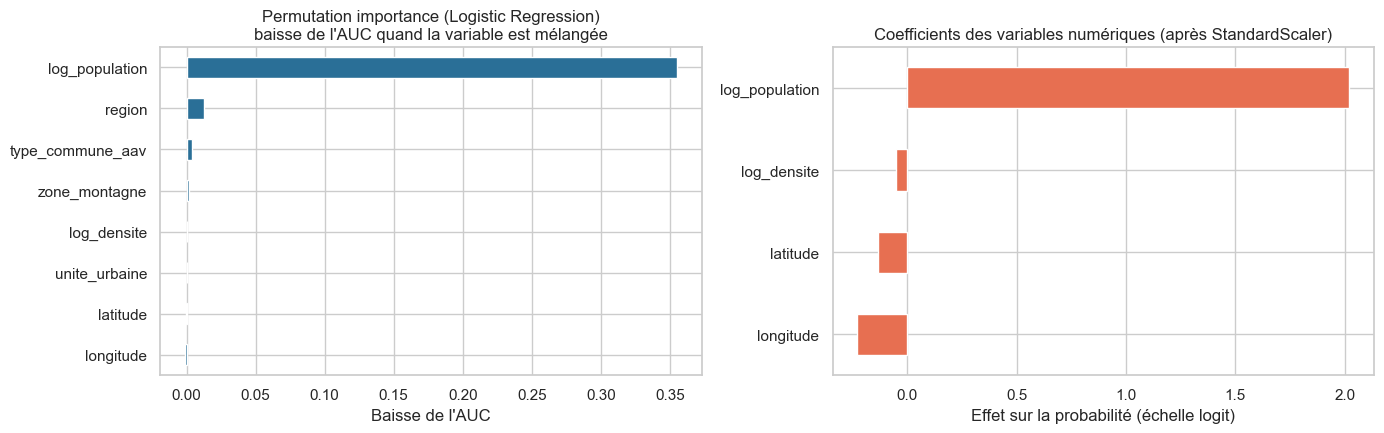

log_population      0.355
region              0.012
type_commune_aav    0.004
zone_montagne       0.002
log_densite         0.001
unite_urbaine      -0.000
latitude           -0.001
longitude          -0.001


In [6]:
importance = permutation_importance(modele_retenu, X_test, y_test, scoring="roc_auc",
                                    n_repeats=10, random_state=GRAINE)
importances = pd.Series(importance.importances_mean, index=X_test.columns).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
importances.plot.barh(ax=axes[0], color="#2a6f97")
axes[0].set(title=f"Permutation importance ({retenu})\nbaisse de l'AUC quand la variable est mélangée",
            xlabel="Baisse de l'AUC", ylabel="")
if retenu == "Logistic Regression":
  noms = modele_retenu.named_steps["preparation"].get_feature_names_out()
  coefficients = pd.Series(modele_retenu.named_steps["modele"].coef_[0], index=noms)
  coefficients = coefficients[coefficients.index.str.startswith("numeriques")].rename(
      lambda n: n.replace("numeriques__", ""))
  coefficients.sort_values().plot.barh(ax=axes[1], color="#e76f51")
  axes[1].set(title="Coefficients des variables numériques (après StandardScaler)",
              xlabel="Effet sur la probabilité (échelle logit)", ylabel="")
plt.tight_layout()
plt.show()
print(importances.sort_values(ascending=False).round(3).to_string())


**Lecture.**
- La population domine : en permutation importance, la mélanger fait perdre 0,355 point d'AUC, contre 0,012 pour la région et moins de 0,005 pour toutes les autres variables.
- Le coefficient de la population est fortement positif : plus une commune est peuplée, plus elle a de chances d'être équipée. Les autres coefficients sont proches de zéro.
- **Conclusion pour la problématique** : le déploiement des points de charge suit la population. Une fois la population connue, la densité, le relief ou le type de commune n'expliquent presque rien de plus.

## Scoring : communes sans borne au profil de commune équipée

Chaque probabilité est calculée par un modèle qui n'a jamais vu le département de la commune (prédictions out-of-fold de `cross_val_predict`, cross-validation par groupes de départements).

In [7]:
# Probabilité de chaque commune calculée par un modèle qui n'a pas vu son département
proba = cross_val_predict(modele_retenu, X, y, cv=validation, groups=groupes, method="predict_proba")[:, 1]
metropole["probabilite_equipee"] = proba
sans_point = metropole.loc[metropole["nb_pdc"] == 0]
for seuil in [0.5, 0.7, 0.9]:
  candidates = sans_point["probabilite_equipee"] > seuil
  print(f"Communes sans point avec une probabilité > {seuil} : {candidates.sum():,} "
        f"({sans_point.loc[candidates, 'population'].sum():,} habitants)")
prioritaires = sans_point.nlargest(15, "probabilite_equipee")[
    ["code_insee", "nom_commune", "code_departement", "population", "type_commune_aav",
     "distance_pdc_km", "probabilite_equipee"]]
print("\nCommunes sans point dont le profil ressemble le plus à celui des communes équipées :")
print(prioritaires.round(2).to_string(index=False))
par_departement = sans_point.loc[sans_point["probabilite_equipee"] > 0.7].groupby(
    "code_departement").agg(communes=("code_insee", "size"), habitants=("population", "sum"))
print("\nDépartements comptant le plus de communes prioritaires (probabilité > 0,7) :")
print(par_departement.sort_values("habitants", ascending=False).head(10).to_string())


Communes sans point avec une probabilité > 0.5 : 1,777 (3,405,309 habitants)
Communes sans point avec une probabilité > 0.7 : 557 (1,619,084 habitants)
Communes sans point avec une probabilité > 0.9 : 54 (287,275 habitants)

Communes sans point dont le profil ressemble le plus à celui des communes équipées :
code_insee              nom_commune code_departement  population                   type_commune_aav  distance_pdc_km  probabilite_equipee
     77464       Thorigny-sur-Marne               77       10440    Autre commune du pôle principal             1.26                 0.98
     21617                   Talant               21       11896    Autre commune du pôle principal             0.52                 0.96
     06105       Roquefort-les-Pins               06        7292             Commune de la couronne             3.25                 0.96
     71486            Saint-Vallier               71        8503    Autre commune du pôle principal             3.09                 0.96


**Lecture.**
- 557 communes sans aucun point ont une probabilité d'équipement supérieure à 0,7 : elles regroupent 1,62 million d'habitants. Au seuil de 0,9, il en reste 54 (287 275 habitants).
- Ce sont surtout des bourgs de la couronne des villes : 77 % sont des communes de la couronne d'une aire d'attraction, et la moitié compte entre 2 066 et 3 360 habitants (médiane 2 578). Les plus probables sont plus peuplées : Thorigny-sur-Marne (10 440 habitants) et Saint-Pathus en Seine-et-Marne, Talant près de Dijon, La Bouilladisse près de Marseille.
- La plupart ne sont pas des déserts au sens de la distance : pour 79,4 % d'entre elles, un point de charge existe à moins de 5 km (médiane 3,3 km), et seules 8 sont des déserts de recharge. Le modèle repère un **sous-équipement relatif** (une commune de cette taille est habituellement équipée), pas un éloignement.
- Les départements qui en comptent le plus en population sont le Nord, la Vendée, le Pas-de-Calais et l'Ille-et-Vilaine.

**Limite.** Le modèle apprend la logique du déploiement actuel, y compris ses biais : une commune « attendue » équipée ne l'est pas forcément faute de besoin. La liste est une aide à la décision, à croiser avec la connaissance du terrain.

## Contrôle du domaine d'application

In [8]:
# Contrôle du domaine : les communes d'outre-mer sortent-elles des valeurs vues à l'entraînement ?
bornes = metropole[VARIABLES_NUMERIQUES].agg(["min", "max"])
hors_domaine = donnees.loc[outre_mer, VARIABLES_NUMERIQUES].apply(
    lambda col: (col < bornes.loc["min", col.name]) | (col > bornes.loc["max", col.name]))
print(f"Communes d'outre-mer : {outre_mer.sum()} | hors du domaine d'entraînement pour au moins une "
      f"variable : {hors_domaine.any(axis=1).sum()}")
print("Variables concernées :", hors_domaine.sum().to_dict())


Communes d'outre-mer : 129 | hors du domaine d'entraînement pour au moins une variable : 129
Variables concernées : {'log_population': 0, 'log_densite': 2, 'latitude': 129, 'longitude': 129}


**Lecture.** Les 129 communes d'outre-mer ont toutes une latitude et une longitude hors des valeurs vues à l'entraînement (et 2 une densité hors domaine). Appliquer le modèle à ces territoires reviendrait à extrapoler : il n'est donc pas utilisé outre-mer, où le diagnostic repose sur l'analyse exploratoire (absence de points de 150 kW aux Antilles, en Guyane et à Mayotte).

# Clustering : typologie des stations (K-Means)

**Question.** Quels grands types de stations composent le réseau, et comment se répartissent-ils sur le territoire ? Le clustering est **non supervisé** : il n'y a pas de target, l'algorithme regroupe les stations qui se ressemblent.

**Observation.** La station (49 180 stations), décrite à partir de ses points de charge.

**Features.**

| Feature | Ce qu'elle décrit |
|---|---|
| Nombre de points (logarithme) | Taille de la station |
| Puissance maximale (logarithme) | Niveau de puissance |
| Part de points en courant continu (prise combo CCS ou CHAdeMO, ou plus de 43 kW) | Recharge rapide ou non |
| Part de points avec prise domestique (EF) | Bornes d'appoint |
| Part de points en accès libre | Public ou réservé |
| Population de la commune (logarithme) | Contexte urbain ou rural |

Le type d'implantation (voirie, parking, station dédiée) sert à **décrire** les clusters, pas à les construire : c'est la variable la moins fiable du jeu (les producteurs se contredisent pour 41,2 % des points publiés plusieurs fois).

**Preprocessing.** K-Means mesure des distances : sans mise à l'échelle, la feature aux plus grandes valeurs dominerait. Les features passent donc par un StandardScaler, dans un pipeline.

**Choix du nombre de clusters (k).** Trois critères, de k = 2 à 8 :
- **inertie** (méthode du coude) : somme des distances au carré entre chaque station et le centre de son cluster ; elle baisse toujours quand k augmente, on cherche le point où la baisse ralentit ;
- **silhouette** (de −1 à 1) : une station est-elle plus proche de son cluster que du cluster voisin ? Calculée sur 15 000 stations tirées au hasard ;
- **stabilité** : Adjusted Rand Index (ARI) entre 5 initialisations différentes ; 1 = mêmes groupes à chaque fois.

In [9]:
CHEMIN_POINTS = Path("../data/processed/irve_points_clean.csv")
PRISES = ["prise_type_2", "prise_type_combo_ccs", "prise_type_chademo", "prise_type_ef"]

points = pd.read_csv(CHEMIN_POINTS, dtype={"id_pdc": str, "id_station": str, "code_insee": str})
points[PRISES] = points[PRISES].astype(bool)
points["courant_continu"] = (points["prise_type_combo_ccs"] | points["prise_type_chademo"]
                             | (points["puissance_kw"] > 43))
points["acces_libre"] = points["condition_acces"] == "Accès libre"

stations = points.groupby("id_station").agg(
    nb_pdc=("id_pdc", "size"), puissance_max=("puissance_kw", "max"),
    part_dc=("courant_continu", "mean"), part_ef=("prise_type_ef", "mean"),
    part_acces_libre=("acces_libre", "mean"),
    implantation=("implantation_station", lambda s: s.mode().iat[0]),
    code_insee=("code_insee", lambda s: s.mode().iat[0]))
stations["population_commune"] = stations["code_insee"].map(
    communes.set_index("code_insee")["population"]).fillna(0)
stations = stations.merge(communes[["code_insee", "region"]], on="code_insee", how="left").set_index(stations.index)

FEATURES_CLUSTERING = ["log_nb_pdc", "log_puissance_max", "part_dc", "part_ef",
                       "part_acces_libre", "log_population_commune"]
stations["log_nb_pdc"] = np.log1p(stations["nb_pdc"])
stations["log_puissance_max"] = np.log(stations["puissance_max"])
stations["log_population_commune"] = np.log1p(stations["population_commune"])
X_stations = stations[FEATURES_CLUSTERING]
print(f"Stations : {len(stations):,} | features : {X_stations.shape[1]} | "
      f"valeurs manquantes : {X_stations.isna().sum().sum()}")
print(X_stations.describe().round(2).to_string())

Stations : 49,180 | features : 6 | valeurs manquantes : 0
       log_nb_pdc  log_puissance_max   part_dc   part_ef  part_acces_libre  log_population_commune
count    49180.00           49180.00  49180.00  49180.00           49180.0                49180.00
mean         1.25               3.35      0.24      0.40               0.9                    8.99
std          0.56               1.02      0.38      0.47               0.3                    1.86
min          0.69              -6.21      0.00      0.00               0.0                    0.00
25%          0.69               3.09      0.00      0.00               1.0                    7.68
50%          1.10               3.09      0.00      0.00               1.0                    8.80
75%          1.61               3.58      0.50      1.00               1.0                   10.20
max          6.23               6.40      1.00      1.00               1.0                   14.56


## Choix du nombre de clusters

   inertie  silhouette  ARI entre 5 graines  plus petit cluster (%)  baisse d'inertie
k                                                                                    
2   206793       0.328                1.000                    31.1              <NA>
3   167349       0.365                0.968                     9.1             39444
4   133599       0.332                0.999                     8.8             33750
5   116904       0.330                1.000                     8.3             16695
6   104714       0.324                0.997                     8.3             12190
7    95101       0.340                0.998                     2.4              9613
8    87151       0.335                0.852                     2.4              7950


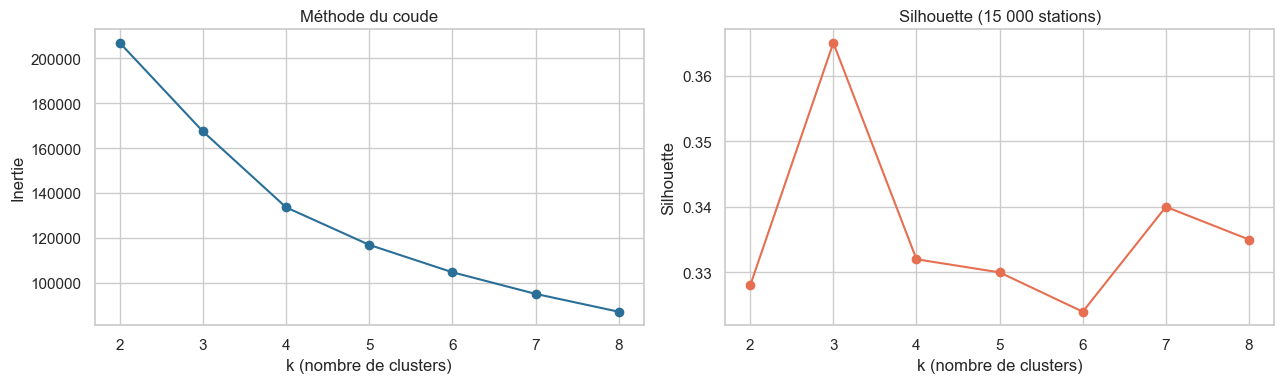

In [10]:
X_echelle = StandardScaler().fit_transform(X_stations)
echantillon = np.random.default_rng(GRAINE).choice(len(X_echelle), 15000, replace=False)
choix_k = []
for k in range(2, 9):
  etiquettes = [KMeans(n_clusters=k, n_init=10, random_state=GRAINE + i).fit_predict(X_echelle) for i in range(5)]
  modele_k = KMeans(n_clusters=k, n_init=10, random_state=GRAINE).fit(X_echelle)
  choix_k.append({
      "k": k, "inertie": round(modele_k.inertia_),
      "silhouette": round(silhouette_score(X_echelle[echantillon], modele_k.labels_[echantillon]), 3),
      "ARI entre 5 graines": round(np.mean([adjusted_rand_score(etiquettes[0], e) for e in etiquettes[1:]]), 3),
      "plus petit cluster (%)": round(np.bincount(modele_k.labels_).min() / len(X_echelle) * 100, 1)})
choix_k = pd.DataFrame(choix_k).set_index("k")
choix_k["baisse d'inertie"] = (-choix_k["inertie"].diff()).astype("Int64")
print(choix_k.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(choix_k.index, choix_k["inertie"], marker="o", color="#2a6f97")
axes[0].set(title="Méthode du coude", xlabel="k (nombre de clusters)", ylabel="Inertie")
axes[1].plot(choix_k.index, choix_k["silhouette"], marker="o", color="#e76f51")
axes[1].set(title="Silhouette (15 000 stations)", xlabel="k (nombre de clusters)", ylabel="Silhouette")
plt.tight_layout()
plt.show()

**Lecture.**
- L'inertie baisse de 39 444 en passant de 2 à 3 clusters, de 33 750 de 3 à 4, puis seulement de 16 695 de 4 à 5 : le coude est à **k = 4**.
- La silhouette reste entre 0,32 et 0,37 quel que soit k : les groupes existent, mais leurs frontières sont floues (structure modérée) ; beaucoup de stations ont un profil intermédiaire.
- k = 3 a la meilleure silhouette (0,365), mais il réunit les deux types de bornes en courant alternatif (avec et sans prise domestique) dans un même groupe de 61 % des stations : la typologie perd l'essentiel de son information.
- À k = 4, les groupes sont identiques d'une initialisation à l'autre (ARI 0,999) et le plus petit regroupe 8,8 % des stations.

**k = 4 est retenu.**

## Typologie retenue

                                       stations  part_stations_%  points_medians  puissance_max_mediane  part_dc  part_ef  part_acces_libre  population_commune_mediane
cluster                                                                                                                                                                
AC de proximité avec prise domestique     16741             34.0             2.0                   22.0     0.02     0.99              1.00                      4724.0
Recharge rapide DC                        11940             24.3             4.0                  150.0     0.81     0.06              0.94                      7919.0
AC urbaine                                16174             32.9             2.0                   22.0     0.09     0.07              1.00                      9200.5
Accès réservé                              4325              8.8             1.0                   22.0     0.09     0.33              0.00                     

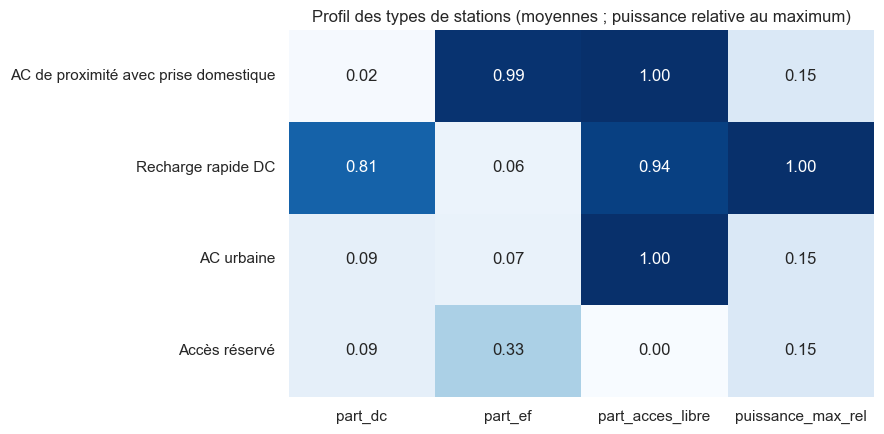

In [11]:
K_RETENU = 4
clustering = Pipeline([("echelle", StandardScaler()),
                       ("kmeans", KMeans(n_clusters=K_RETENU, n_init=10, random_state=GRAINE))])
stations["cluster"] = clustering.fit_predict(X_stations)

profil = stations.groupby("cluster").agg(
    stations=("nb_pdc", "size"), points_medians=("nb_pdc", "median"),
    puissance_max_mediane=("puissance_max", "median"), part_dc=("part_dc", "mean"),
    part_ef=("part_ef", "mean"), part_acces_libre=("part_acces_libre", "mean"),
    population_commune_mediane=("population_commune", "median"))

# Nom de chaque cluster d'après son profil (les numéros de K-Means sont arbitraires)
noms_clusters = {profil["part_dc"].idxmax(): "Recharge rapide DC",
                 profil["part_acces_libre"].idxmin(): "Accès réservé"}
autres = profil.drop(index=list(noms_clusters))
noms_clusters[autres["part_ef"].idxmax()] = "AC de proximité avec prise domestique"
noms_clusters[autres["part_ef"].idxmin()] = "AC urbaine"
assert len(noms_clusters) == K_RETENU
stations["type_station"] = stations["cluster"].map(noms_clusters)
profil = profil.rename(index=noms_clusters)
profil.insert(1, "part_stations_%", (profil["stations"] / len(stations) * 100).round(1))
print(profil.round(2).to_string())

print("\nImplantation déclarée par type de station (% des stations du type) :")
print((pd.crosstab(stations["type_station"], stations["implantation"], normalize="index") * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(profil[["part_dc", "part_ef", "part_acces_libre"]].assign(
    puissance_max_rel=profil["puissance_max_mediane"] / profil["puissance_max_mediane"].max()),
    annot=True, fmt=".2f", cmap="Blues", ax=ax, cbar=False)
ax.set(title="Profil des types de stations (moyennes ; puissance relative au maximum)", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

**Lecture : quatre types de stations.**
- **AC de proximité avec prise domestique** (34,0 % des stations) : 2 points, 22 kW, prise domestique dans 99 % des cas ; installées sur la voirie à 69,5 %, dans des communes plutôt petites (médiane 4 724 habitants).
- **AC urbaine** (32,9 %) : 2 points, 22 kW, sans prise domestique ; communes plus peuplées (médiane 9 200 habitants), en parking (54 %) ou sur la voirie (44 %).
- **Recharge rapide DC** (24,3 %) : 4 points, puissance maximale médiane de 150 kW, 81 % des points en courant continu. Seules 17,3 % de ces stations sont déclarées « station dédiée à la recharge rapide » : l'implantation déclarée ne suffit pas à repérer la recharge rapide.
- **Accès réservé** (8,8 %) : 1 point, 22 kW, accès réservé (clientèle, résidents). 62,7 % sont pourtant déclarées sur la voirie : l'implantation déclarée est peu cohérente avec l'accès, ce qui confirme sa faible fiabilité.

Le clustering sépare donc deux familles : la recharge lente en courant alternatif (deux types, 66,9 % des stations) et la recharge rapide en courant continu (24,3 %).

## Répartition des types de stations sur le territoire

In [12]:
TRANCHES_POPULATION = [0, 500, 2000, 10000, np.inf]
NOMS_TRANCHES = ["< 500 hab", "500 à 2 000", "2 000 à 10 000", "≥ 10 000"]
stations["taille_commune"] = pd.cut(stations["population_commune"], TRANCHES_POPULATION,
                                    labels=NOMS_TRANCHES, right=False)
print("Types de stations selon la taille de la commune (% des stations de la tranche) :")
print((pd.crosstab(stations["taille_commune"], stations["type_station"], normalize="index", margins=True)
       * 100).round(1).to_string())

par_region = pd.crosstab(stations["region"], stations["type_station"], normalize="index") * 100
print("\nPart des stations de recharge rapide DC par région (%) :")
print(par_region["Recharge rapide DC"].sort_values(ascending=False).round(1).to_string())

Types de stations selon la taille de la commune (% des stations de la tranche) :


type_station    AC de proximité avec prise domestique  AC urbaine  Accès réservé  Recharge rapide DC
taille_commune                                                                                      
< 500 hab                                        37.9        29.2           14.1                18.8
500 à 2 000                                      42.3        28.4            9.9                19.4
2 000 à 10 000                                   36.2        29.3            8.3                26.2
≥ 10 000                                         28.0        38.3            8.1                25.6
All                                              34.0        32.9            8.8                24.3

Part des stations de recharge rapide DC par région (%) :
region
Bourgogne-Franche-Comté       38.4
Martinique                    36.8
Bretagne                      31.1
Auvergne-Rhône-Alpes          28.3
Occitanie                     27.8
Hauts-de-France               26.9
Pays de la Loire  

**Lecture.**
- Les communes de moins de 2 000 habitants sont équipées surtout de bornes AC de proximité avec prise domestique (37,9 % des stations sous 500 habitants, 42,3 % de 500 à 2 000) ; les villes de 10 000 habitants et plus, de bornes AC urbaines (38,3 %).
- La recharge rapide n'est pas réservée aux villes : 18,8 % des stations des communes de moins de 500 habitants sont de ce type, contre 25,6 % dans les communes de 10 000 habitants et plus.
- L'accès réservé est plus fréquent dans les très petites communes (14,1 % des stations, contre 8,1 % au-delà de 10 000 habitants).
- Par région, la Bourgogne-Franche-Comté a la plus forte part de stations de recharge rapide (38,4 %), en cohérence avec sa part de points de 150 kW et plus (27,2 %, analyse exploratoire) ; l'Île-de-France est à 18,1 %. La Martinique (36,8 %) ne compte que 19 stations, dont 6 à 47 kW et aucune de 150 kW : c'est un effet de petit effectif. La Guyane et la Guadeloupe n'ont aucune station de ce type.

**Limites.**
- La silhouette modérée (0,33) indique des groupes aux frontières floues : la typologie simplifie un continuum.
- Elle décrit l'offre technique, pas l'usage : elle ne dit pas si une station est utilisée pour le transit, le domicile ou le travail.
- Elle dépend de l'identifiant de station publié et des règles de dédoublonnage du nettoyage.